In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Find how deep a point sits in cortex

`xyz_to_depth` gives the depth of a point below the surface of the isocortex, measured along the Allen streamlines: paths that run from the cortical surface to the white matter, following the cortical layers. It takes an (n, 3) array of coordinates in metres from bregma, ordered ML, AP, DV.

How to cite this: see [Citations](../citations.qmd).

In [2]:
import numpy as np

from iblatlas.atlas import AllenAtlas
from iblatlas.streamlines.utils import xyz_to_depth

ba = AllenAtlas()
xyz = np.array([[-0.002, -0.002, -0.0005],  # ML, AP, DV in metres from bregma
                [-0.002, -0.002, -0.0010],
                [-0.002, -0.002, -0.0015],
                [-0.002, -0.002, -0.0030]])

print(ba.regions.id2acronym(ba.get_labels(xyz)))
print(xyz_to_depth(xyz))
print(xyz_to_depth(xyz, per=False))

['VISa4' 'scwm' 'CA1' 'LP']


[0.44777316        nan        nan        nan]


[434.65442       nan       nan       nan]


With the default `per=True` the depth is a fraction of the cortical thickness, from 0 at the surface to 1 at the white matter; with `per=False` it is in µm from the surface. Points outside the isocortex return NaN, as the white matter (`scwm`), CA1 and LP points do here. A single point is passed as a (1, 3) array. The lookup uses the 25 µm streamlines; `res_um` selects 10 or 50 µm instead.

## Depth of every voxel in a region

The same lookup on the coordinates of every voxel in a region gives a depth map of the region. Here the voxels of MOp, at the Beryl level, are painted on a coronal slice:

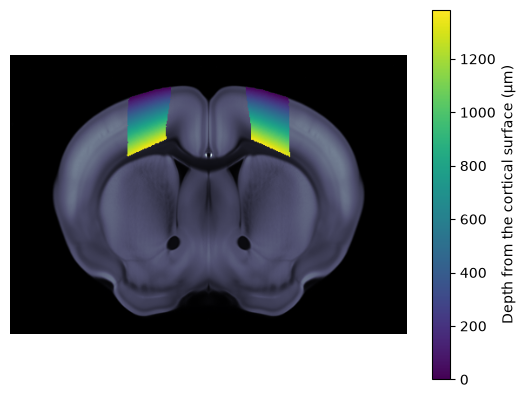

In [3]:
import matplotlib.pyplot as plt

br = ba.regions
mop = np.flatnonzero(br.acronym[br.mappings['Beryl']] == 'MOp')
iap, iml, idv = np.nonzero(np.isin(ba.label, mop))  # volume indices, ordered AP, ML, DV
depth_um = xyz_to_depth(ba.bc.i2xyz(np.c_[iml, iap, idv]), per=False)

depth_volume = np.full(ba.image.shape, np.nan)
depth_volume[iap, iml, idv] = depth_um

fig, ax = plt.subplots()
ba.plot_cslice(620e-6, volume='image', ax=ax)
ba.plot_cslice(620e-6, volume='volume', region_values=depth_volume, ax=ax, cmap='viridis', vmin=0)
ax.set_axis_off()
fig.colorbar(ax.get_images()[1], ax=ax, label='Depth from the cortical surface (µm)');

To draw values on the dorsal cortex flat map, see [Show values per point or cell](plot-points-on-slices.ipynb#on-the-dorsal-cortex-flat-map) and [Show a 3D volume](plot-volumes-on-slices.ipynb#on-the-dorsal-cortex-flat-map).